<a href="https://colab.research.google.com/github/elianpuuig/AM2/blob/main/ConduccionAutonoma_Highway_v0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabajo Práctico: Aprendizaje por Refuerzo en FrozenLake

## Instalar librerias

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from collections import deque
import random
import seaborn as sns
from IPython.display import clear_output
import warnings
warnings.filterwarnings('ignore')

## Reproducibilidad

In [3]:
np.random.seed(42)
torch.manual_seed(42)
random.seed(42)

## Crear el entorno

In [4]:
env = gym.make('FrozenLake-v1', desc=None, map_name="4x4", is_slippery=True, render_mode='ansi')
print("🏔️ ENTORNO FROZENLAKE")
print("=" * 50)
print(f"Número de estados: {env.observation_space.n}")
print(f"Número de acciones: {env.action_space.n}")
print(f"Acciones: {['Izquierda', 'Abajo', 'Derecha', 'Arriba']}")

🏔️ ENTORNO FROZENLAKE
Número de estados: 16
Número de acciones: 4
Acciones: ['Izquierda', 'Abajo', 'Derecha', 'Arriba']


## Mostrar el mapa

In [5]:
print("\n🗺️ MAPA DEL ENTORNO:")
env.reset()
print(env.render())
print("\nLeyenda:")
print("S = Start (Inicio)")
print("F = Frozen (Hielo seguro)")
print("H = Hole (Hoyo - termina episodio)")
print("G = Goal (Objetivo - +1 recompensa)")


🗺️ MAPA DEL ENTORNO:

SFFF
FHFH
FFFH
HFFG


Leyenda:
S = Start (Inicio)
F = Frozen (Hielo seguro)
H = Hole (Hoyo - termina episodio)
G = Goal (Objetivo - +1 recompensa)


## Función para convertir estado numérico a posición (fila, columna)

In [6]:

def estado_a_posicion(estado):
  return estado // 4, estado % 4

## Funcion para visualizar politica

In [7]:
def visualizar_politica(policy, title="Política"):
  acciones_simbolos = ['←', '↓', '→', '↑']
  grid = np.array(acciones_simbolos)[policy].reshape(4, 4)
  plt.figure(figsize=(6, 6))
  plt.imshow(np.ones((4, 4)), cmap='Blues', alpha=0.3)

  for i in range(4):
      for j in range(4):
          estado = i * 4 + j
          if estado == 0:  # Start
              plt.text(j, i, f'S\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold')
          elif estado == 15:  # Goal
              plt.text(j, i, f'G\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold')
          elif estado in [5, 7, 11, 12]:  # Holes
              plt.text(j, i, f'H\n{grid[i,j]}', ha='center', va='center', fontsize=14, fontweight='bold', color='red')
          else:
              plt.text(j, i, grid[i,j], ha='center', va='center', fontsize=16)

  plt.xlim(-0.5, 3.5)
  plt.ylim(-0.5, 3.5)
  plt.xticks([])
  plt.yticks([])
  plt.title(title, fontsize=16)
  plt.grid(True, alpha=0.3)
  plt.show()

## Politica aleatoria

In [8]:
class PoliticaAleatoria:
  """Política que selecciona acciones completamente al azar"""
  def __init__(self, n_acciones):
      self.n_acciones = n_acciones
      self.nombre = "Política Aleatoria"

  def seleccionar_accion(self, estado):
      """Selecciona una acción aleatoria"""
      return np.random.randint(self.n_acciones)

  def entrenar(self, env, episodios=1000):
      """La política aleatoria no se entrena, solo evaluamos su desempeño"""
      print(f"🎲 Evaluando {self.nombre}...")
      recompensas = []
      exitos = 0

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado)
              estado, recompensa, terminado, truncated, _ = env.step(accion)
              recompensa_total += recompensa
              pasos += 1

              if truncated:
                  terminado = True

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)

          if (episodio + 1) % 200 == 0:
              tasa_exito = exitos / (episodio + 1)
              print(f"Episodio {episodio + 1}: Tasa de éxito = {tasa_exito:.3f}")

      tasa_exito_final = exitos / episodios
      print(f"\n📊 Resultados {self.nombre}:")
      print(f"Tasa de éxito final: {tasa_exito_final:.3f}")
      print(f"Recompensa promedio: {np.mean(recompensas):.3f}")

      return recompensas, tasa_exito_final

## Crear y evaluar política aleatoria

In [9]:
agente_aleatorio = PoliticaAleatoria(env.action_space.n)
recompensas_aleatorio, tasa_exito_aleatorio = agente_aleatorio.entrenar(env, episodios=1000)

🎲 Evaluando Política Aleatoria...
Episodio 200: Tasa de éxito = 0.015
Episodio 400: Tasa de éxito = 0.013
Episodio 600: Tasa de éxito = 0.012
Episodio 800: Tasa de éxito = 0.010
Episodio 1000: Tasa de éxito = 0.009

📊 Resultados Política Aleatoria:
Tasa de éxito final: 0.009
Recompensa promedio: 0.009


## Visualizar política aleatoria (todas las acciones tienen la misma probabilidad)

In [10]:

politica_aleatoria = np.random.randint(0, 4, 16)  # Solo para visualización

In [11]:
politica_aleatoria

array([2, 1, 0, 0, 3, 0, 1, 0, 1, 0, 2, 3, 3, 2, 2, 3])

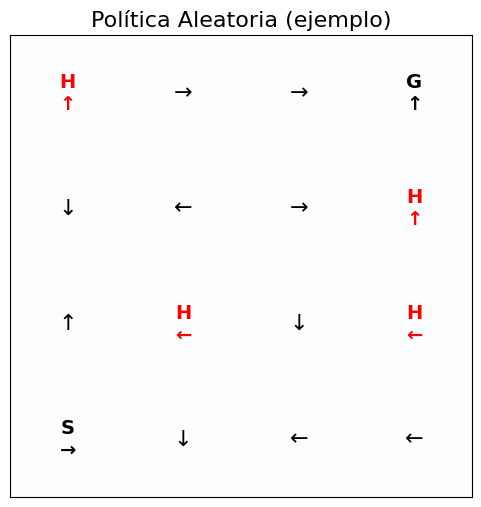

In [12]:

visualizar_politica(politica_aleatoria, "Política Aleatoria (ejemplo)")

## Politica Q-learning

In [13]:
class QLearningTabular:
  """Implementación de Q-Learning con tabla Q explícita"""
  def __init__(self, n_estados, n_acciones, lr=0.1, gamma=0.95, epsilon=1.0):
      self.n_estados = n_estados
      self.n_acciones = n_acciones
      self.lr = lr  # learning rate
      self.gamma = gamma  # factor de descuento
      self.epsilon = epsilon  # exploración inicial
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.nombre = "Q-Learning Tabular"

      # Inicializar tabla Q
      self.q_table = np.zeros((n_estados, n_acciones))




      # Para tracking
      self.recompensas_entrenamiento = []
      self.epsilons = []

  def seleccionar_accion(self, estado, entrenando=True):
      """Selección de acción con epsilon-greedy"""
      estado.discretizar()
      if entrenando and np.random.random() < self.epsilon:
          return np.random.randint(self.n_acciones)  # Exploración
      else:
          return np.argmax(self.q_table[estado])  # Explotación

  def actualizar_q(self, estado, accion, recompensa, siguiente_estado, terminado):
      """Actualización de la tabla Q usando la ecuación de Bellman"""
      # Target Q-value
      if terminado:
          target = recompensa
      else:
          target = recompensa + self.gamma * np.max(self.q_table[siguiente_estado])

      # Actualización Q-Learning
      self.q_table[estado, accion] += self.lr * (target - self.q_table[estado, accion])

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
      """Obtener la política greedy de la tabla Q"""
      return np.argmax(self.q_table, axis=1)

  def entrenar(self, env, episodios=10000):
      """Entrenamiento del agente Q-Learning"""
      print(f"🧠 Entrenando {self.nombre}...")

      recompensas = []
      exitos_ventana = deque(maxlen=100)  # Para promedios móviles

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              # Actualizar tabla Q
              self.actualizar_q(estado, accion, recompensa, siguiente_estado, terminado)

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)

          # Decay epsilon
          self.decay_epsilon()

          # Logging
          if (episodio + 1) % 1000 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito (últimos 100) = {tasa_exito:.3f}, Epsilon = {self.epsilon:.3f}")

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
      """Evaluación del agente entrenado sin exploración"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)  # Sin exploración
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

## Crear y entrenar agente Q-Learning

In [14]:

agente_qlearning = QLearningTabular(env.observation_space.n, env.action_space.n,lr=0.1, gamma=0.95, epsilon=1.0)
recompensas_qlearning = agente_qlearning.entrenar(env, episodios=1000)

🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.570, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!


## Evaluar agente entrenado

In [15]:

tasa_exito_qlearning, _ = agente_qlearning.evaluar(env, episodios=1000)


📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.462
Pasos promedio: 30.1


## Visualizar política aprendida

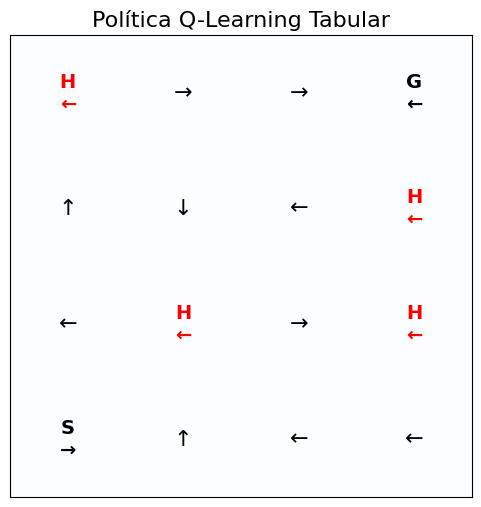

In [16]:

politica_qlearning = agente_qlearning.obtener_politica()
visualizar_politica(politica_qlearning, "Política Q-Learning Tabular")

## Visualizar tabla Q como heatmap

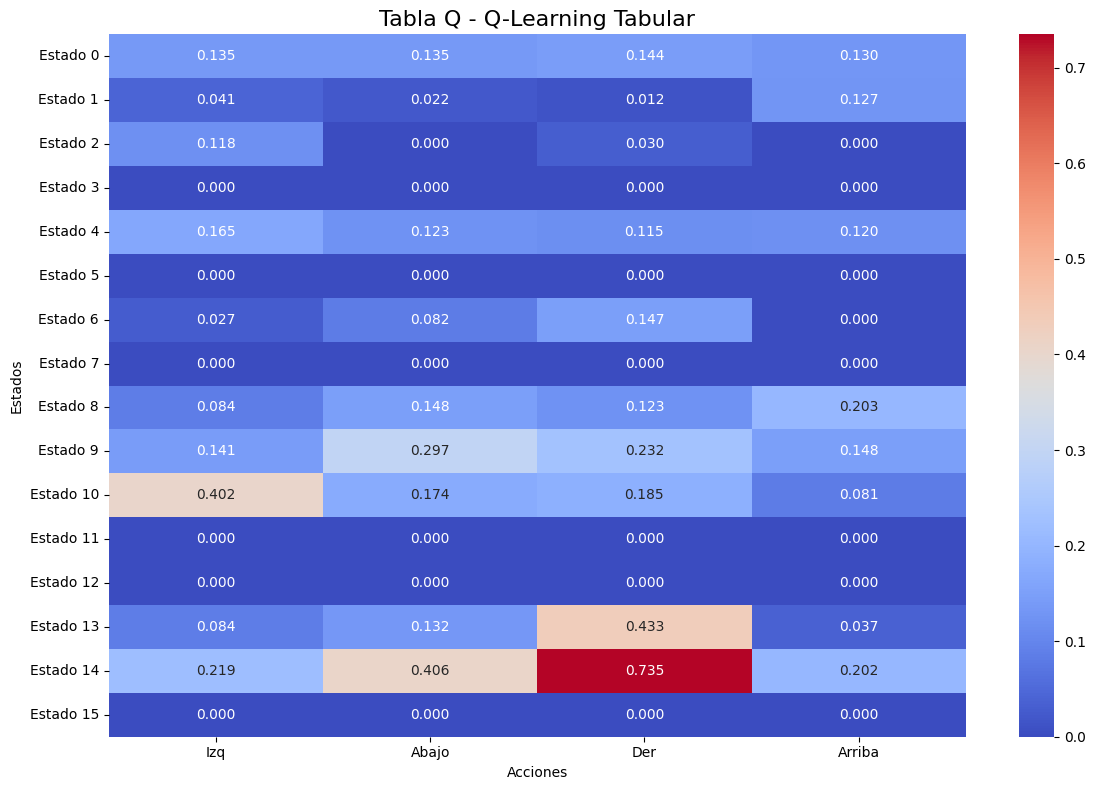

In [17]:

plt.figure(figsize=(12, 8))
sns.heatmap(agente_qlearning.q_table, annot=True, fmt='.3f', cmap='coolwarm',
xticklabels=['Izq', 'Abajo', 'Der', 'Arriba'],
yticklabels=[f'Estado {i}' for i in range(16)])
plt.title('Tabla Q - Q-Learning Tabular', fontsize=16)
plt.xlabel('Acciones')
plt.ylabel('Estados')
plt.tight_layout()
plt.show()

## Mostrar valores Q para estados importantes
-

In [18]:
print("🎯 VALORES Q PARA ESTADOS CLAVE:")
print("-" * 40)
estados_clave = [0, 5, 7, 11, 12, 14, 15]  # Start, Holes, Goal
acciones_nombres = ['Izquierda', 'Abajo', 'Derecha', 'Arriba']
for estado in estados_clave:
  if estado == 0:
    tipo = "START"
  elif estado == 15:
    tipo = "GOAL"
  elif estado in [5, 7, 11, 12]:
    tipo = "HOLE"
  else:
    tipo = "NORMAL"

print(f"\nEstado {estado} ({tipo}):")
for accion, valor in enumerate(agente_qlearning.q_table[estado]):
    print(f"  {acciones_nombres[accion]}: {valor:.3f}")

🎯 VALORES Q PARA ESTADOS CLAVE:
----------------------------------------

Estado 15 (GOAL):
  Izquierda: 0.000
  Abajo: 0.000
  Derecha: 0.000
  Arriba: 0.000


# Deep Q-Network

## red DQN

In [19]:
class DQN(nn.Module):
  """Red neuronal para aproximar la función Q"""
  def __init__(self, input_size, hidden_size, output_size):
      super(DQN, self).__init__()
      self.network = nn.Sequential(
          nn.Linear(input_size, hidden_size),
          nn.ReLU(),
          nn.Linear(hidden_size, hidden_size),
          nn.ReLU(),
          nn.Linear(hidden_size, output_size)
      )

  def forward(self, x):
      return self.network(x)

## DQNAgent

In [20]:
class DQNAgent:
  """Agente Deep Q-Network con Experience Replay y Target Network"""
  def __init__(self, state_size, action_size, lr=0.001, gamma=0.95, epsilon=1.0):
      self.state_size = state_size
      self.action_size = action_size
      self.gamma = gamma
      self.epsilon = epsilon
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.learning_rate = lr
      self.nombre = "Deep Q-Network (DQN)"

      # Configuración del dispositivo
      self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
      print(f"🖥️ Usando dispositivo: {self.device}")

      # Redes neuronales
      hidden_size = 128
      self.q_network = DQN(state_size, hidden_size, action_size).to(self.device)
      self.target_network = DQN(state_size, hidden_size, action_size).to(self.device)
      self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)

      # Inicializar target network con mismos pesos
      self.update_target_network()

      # Experience Replay
      self.memory = deque(maxlen=10000)
      self.batch_size = 32

      # Frecuencia de actualización de target network
      self.update_target_frequency = 100
      self.step_count = 0

      # Para tracking
      self.losses = []
      self.recompensas_entrenamiento = []
      self.epsilons = []

  def state_to_onehot(self, state):
      """Convertir estado discreto a representación one-hot"""
      onehot = np.zeros(self.state_size)
      onehot[state] = 1.0
      return onehot

  def remember(self, estado, accion, recompensa, siguiente_estado, terminado):
      """Almacenar experiencia en el buffer de replay"""
      estado_onehot = self.state_to_onehot(estado)
      siguiente_estado_onehot = self.state_to_onehot(siguiente_estado)

      self.memory.append((estado_onehot, accion, recompensa, siguiente_estado_onehot, terminado))

  def seleccionar_accion(self, estado, entrenando=True):
      """Selección de acción epsilon-greedy usando la red neuronal"""
      if entrenando and np.random.random() < self.epsilon:
          return random.randrange(self.action_size)

      # Convertir estado a tensor
      estado_onehot = self.state_to_onehot(estado)
      estado_tensor = torch.FloatTensor(estado_onehot).unsqueeze(0).to(self.device)

      # Forward pass
      with torch.no_grad():
          q_values = self.q_network(estado_tensor)

      return np.argmax(q_values.cpu().data.numpy())

  def replay(self):
      """Experience replay para entrenar la red"""
      if len(self.memory) < self.batch_size:
          return

      # Muestrear batch aleatorio
      batch = random.sample(self.memory, self.batch_size)
      estados = torch.FloatTensor([e[0] for e in batch]).to(self.device)
      acciones = torch.LongTensor([e[1] for e in batch]).to(self.device)
      recompensas = torch.FloatTensor([e[2] for e in batch]).to(self.device)
      siguientes_estados = torch.FloatTensor([e[3] for e in batch]).to(self.device)
      terminados = torch.BoolTensor([e[4] for e in batch]).to(self.device)

      # Q-values actuales
      current_q_values = self.q_network(estados).gather(1, acciones.unsqueeze(1))

      # Q-values objetivo usando target network
      with torch.no_grad():
          next_q_values = self.target_network(siguientes_estados).max(1)[0]
          target_q_values = recompensas + (self.gamma * next_q_values * ~terminados)

      # Calcular pérdida
      loss = F.mse_loss(current_q_values.squeeze(), target_q_values)

      # Backpropagation
      self.optimizer.zero_grad()
      loss.backward()
      self.optimizer.step()

      # Guardar pérdida para análisis
      self.losses.append(loss.item())

  def update_target_network(self):
      """Actualizar la target network con pesos de la red principal"""
      self.target_network.load_state_dict(self.q_network.state_dict())

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
      """Obtener política greedy de la red entrenada"""
      politica = []
      for estado in range(self.state_size):
          accion = self.seleccionar_accion(estado, entrenando=False)
          politica.append(accion)
      return np.array(politica)

  def entrenar(self, env, episodios=2000):
      """Entrenamiento del agente DQN"""
      print(f"🤖 Entrenando {self.nombre}...")

      recompensas = []
      exitos_ventana = deque(maxlen=100)

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              # Almacenar experiencia
              self.remember(estado, accion, recompensa, siguiente_estado, terminado)

              # Entrenar la red
              self.replay()

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1
              self.step_count += 1

              # Actualizar target network periódicamente
              if self.step_count % self.update_target_frequency == 0:
                  self.update_target_network()

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)

          # Decay epsilon
          self.decay_epsilon()

          # Logging
          if (episodio + 1) % 200 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              loss_promedio = np.mean(self.losses[-100:]) if len(self.losses) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito = {tasa_exito:.3f}, "
                    f"Epsilon = {self.epsilon:.3f}, Loss = {loss_promedio:.4f}")

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
      """Evaluación del agente entrenado"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

## Entrenar deep DQN

In [21]:
agente_dqn = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.001, gamma=0.95, epsilon=1.0)
recompensas_dqn = agente_dqn.entrenar(env, episodios=2000)

🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.050, Epsilon = 0.367, Loss = 0.0061
Episodio 400: Tasa éxito = 0.190, Epsilon = 0.135, Loss = 0.0065
Episodio 600: Tasa éxito = 0.450, Epsilon = 0.049, Loss = 0.0077
Episodio 800: Tasa éxito = 0.510, Epsilon = 0.018, Loss = 0.0085
Episodio 1000: Tasa éxito = 0.550, Epsilon = 0.010, Loss = 0.0078
Episodio 1200: Tasa éxito = 0.530, Epsilon = 0.010, Loss = 0.0072
Episodio 1400: Tasa éxito = 0.620, Epsilon = 0.010, Loss = 0.0080
Episodio 1600: Tasa éxito = 0.530, Epsilon = 0.010, Loss = 0.0087
Episodio 1800: Tasa éxito = 0.530, Epsilon = 0.010, Loss = 0.0076
Episodio 2000: Tasa éxito = 0.670, Epsilon = 0.010, Loss = 0.0077

✅ Entrenamiento Deep Q-Network (DQN) completado!


## Evaluar agente Deep DQN

In [22]:
tasa_exito_dqn, _ = agente_dqn.evaluar(env, episodios=1000)


📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.719
Pasos promedio: 42.4


In [23]:
tasa_exito_dqn, _ = agente_dqn.evaluar(env, episodios=1000)

📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.730
Pasos promedio: 41.5


## Visualizar política aprendida

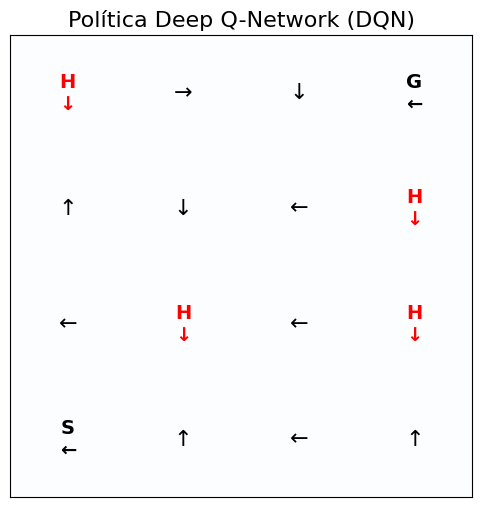

In [24]:

politica_dqn = agente_dqn.obtener_politica()
visualizar_politica(politica_dqn, "Política Deep Q-Network (DQN)")


# Comparación de resultados

## Comparación final tasa de éxito

In [25]:
print("🏆 COMPARACIÓN FINAL DE AGENTES")
print("=" * 50)
print(f"Política Aleatoria:    Tasa de éxito = {tasa_exito_aleatorio:.3f}")
print(f"Q-Learning Tabular:    Tasa de éxito = {tasa_exito_qlearning:.3f}")
print(f"Deep Q-Network (DQN):  Tasa de éxito = {tasa_exito_dqn:.3f}")

🏆 COMPARACIÓN FINAL DE AGENTES
Política Aleatoria:    Tasa de éxito = 0.009
Q-Learning Tabular:    Tasa de éxito = 0.462
Deep Q-Network (DQN):  Tasa de éxito = 0.730


## Crear gráficas de comparación


Crear gráficas de comparación


### 1. Curvas de aprendizaje

In [26]:
len(recompensas_aleatorio)

1000

In [27]:
len(recompensas_qlearning)

1000

In [28]:
len(recompensas_dqn)

2000

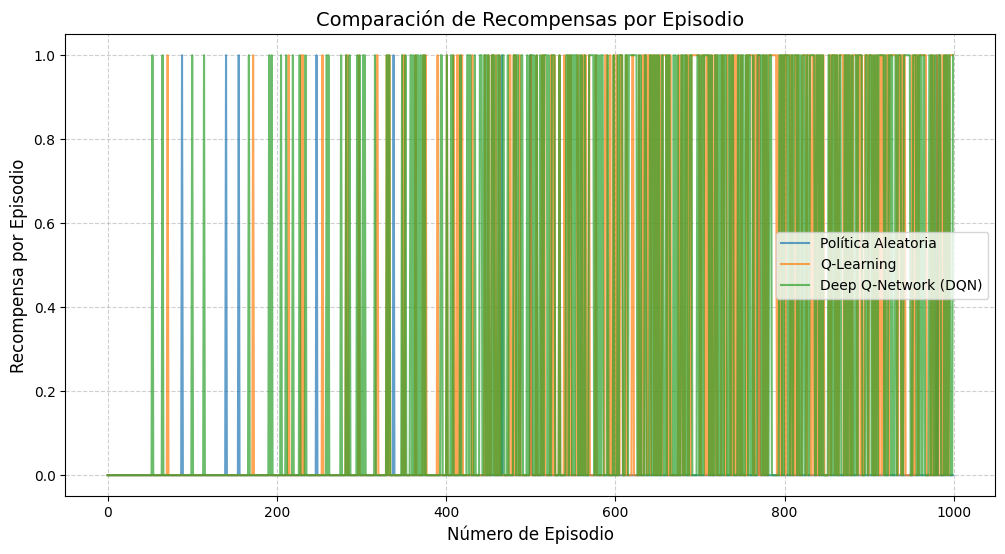

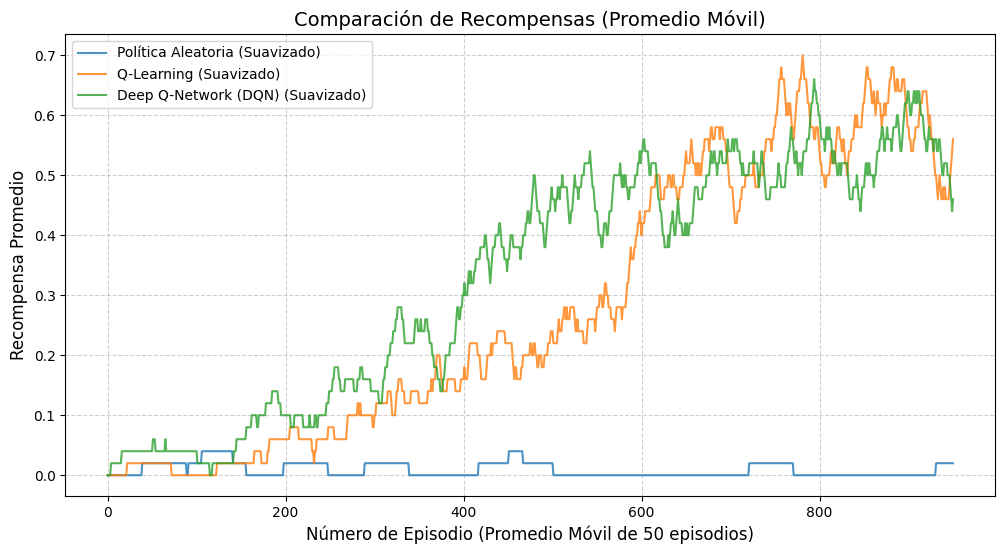

In [29]:
# prompt: crear gráfico que compare recompensas_aleatorio, recompensas_qlearning y recompensas_dqn. Eje x es nro de episodio y el eje Y valor de la recompensa

import matplotlib.pyplot as plt
import numpy as np
# Asegurar que las listas de recompensas tengan la misma longitud para la gráfica
# Tomaremos la longitud mínima si son diferentes
min_len = min(len(recompensas_aleatorio), len(recompensas_qlearning), len(recompensas_dqn))

plt.figure(figsize=(12, 6))
plt.plot(recompensas_aleatorio[:min_len], label='Política Aleatoria', alpha=0.7)
plt.plot(recompensas_qlearning[:min_len], label='Q-Learning', alpha=0.7)
plt.plot(recompensas_dqn[:min_len], label='Deep Q-Network (DQN)', alpha=0.7)

plt.xlabel('Número de Episodio', fontsize=12)
plt.ylabel('Recompensa por Episodio', fontsize=12)
plt.title('Comparación de Recompensas por Episodio', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# Para suavizar la gráfica, se puede usar un promedio móvil
def moving_average(data, window_size):
    if len(data) < window_size:
        return data
    return np.convolve(data, np.ones(window_size)/window_size, mode='valid')

window = 50  # Tamaño de la ventana para el promedio móvil

recompensas_aleatorio_suavizado = moving_average(recompensas_aleatorio, window)
recompensas_qlearning_suavizado = moving_average(recompensas_qlearning, window)
recompensas_dqn_suavizado = moving_average(recompensas_dqn, window)

# Ajustar la longitud mínima para las series suavizadas
min_len_suavizado = min(len(recompensas_aleatorio_suavizado), len(recompensas_qlearning_suavizado), len(recompensas_dqn_suavizado))

plt.figure(figsize=(12, 6))
plt.plot(recompensas_aleatorio_suavizado[:min_len_suavizado], label='Política Aleatoria (Suavizado)', alpha=0.8)
plt.plot(recompensas_qlearning_suavizado[:min_len_suavizado], label='Q-Learning (Suavizado)', alpha=0.8)
plt.plot(recompensas_dqn_suavizado[:min_len_suavizado], label='Deep Q-Network (DQN) (Suavizado)', alpha=0.8)

plt.xlabel(f'Número de Episodio (Promedio Móvil de {window} episodios)', fontsize=12)
plt.ylabel('Recompensa Promedio', fontsize=12)
plt.title('Comparación de Recompensas (Promedio Móvil)', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()



### 2. Comparación de tasas de éxito

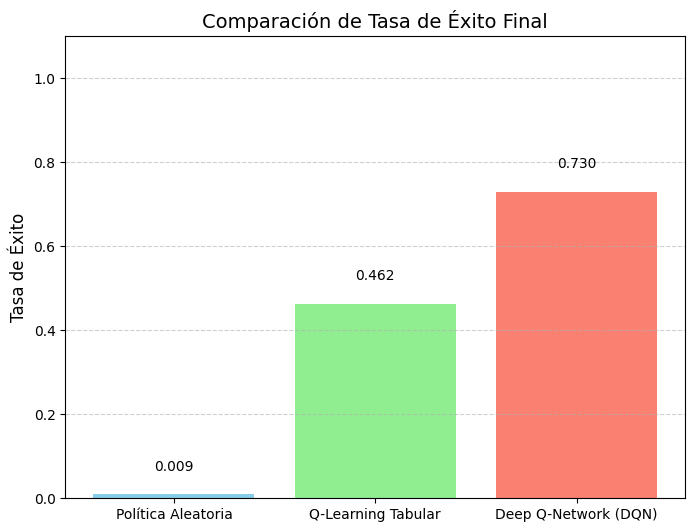

In [30]:
# prompt: comparar tasa_exito_aleatorio, tasa_exito_qlearning, tasa_exito_dqn en un gráfico de barras

import matplotlib.pyplot as plt
metricas = ['Política Aleatoria', 'Q-Learning Tabular', 'Deep Q-Network (DQN)']
tasas_exito = [tasa_exito_aleatorio, tasa_exito_qlearning, tasa_exito_dqn]

plt.figure(figsize=(8, 6))
barras = plt.bar(metricas, tasas_exito, color=['skyblue', 'lightgreen', 'salmon'])
plt.ylabel('Tasa de Éxito', fontsize=12)
plt.title('Comparación de Tasa de Éxito Final', fontsize=14)
plt.ylim(0, 1.1) # Limitar el eje Y de 0 a 1.1 para mejor visualización

# Añadir los valores de las tasas de éxito encima de cada barra
for bar in barras:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f'{yval:.3f}', ha='center', va='bottom', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()


### Evolución de Epsilon (solo para algoritmos que usan exploración)

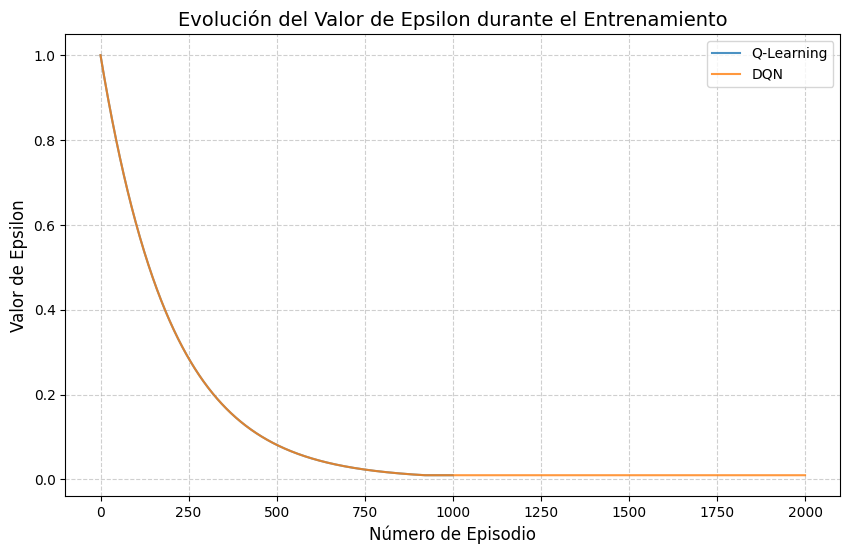

In [31]:
# prompt: Crear un gráfico para comparar agente_qlearning.epsilons y agente_qlearning.epsilons siendo x el nro de episodios y el eje Y el valor de epsilon

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(agente_qlearning.epsilons, label='Q-Learning', alpha=0.8)
plt.plot(agente_dqn.epsilons, label='DQN', alpha=0.8)

plt.xlabel('Número de Episodio', fontsize=12)
plt.ylabel('Valor de Epsilon', fontsize=12)
plt.title('Evolución del Valor de Epsilon durante el Entrenamiento', fontsize=14)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### DQN pérdida

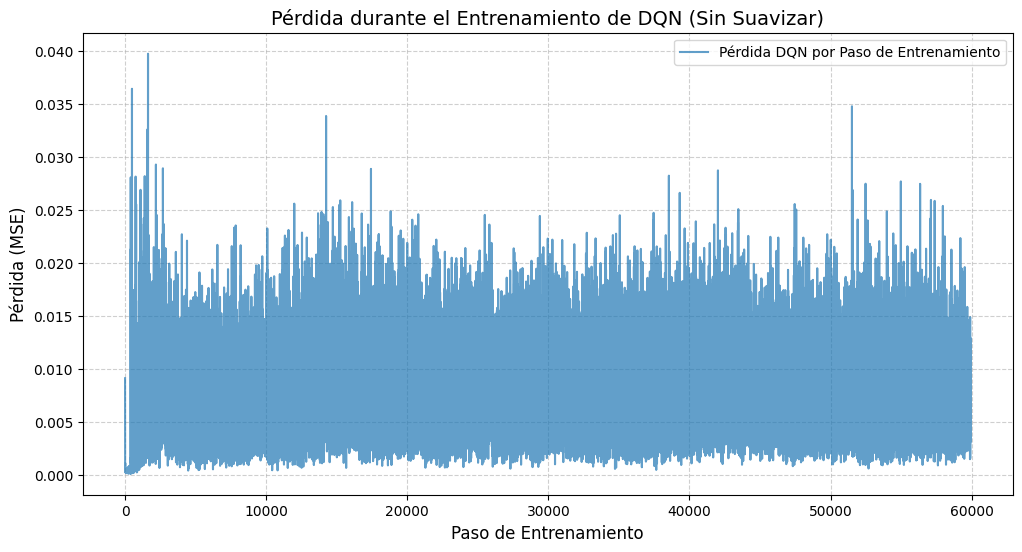

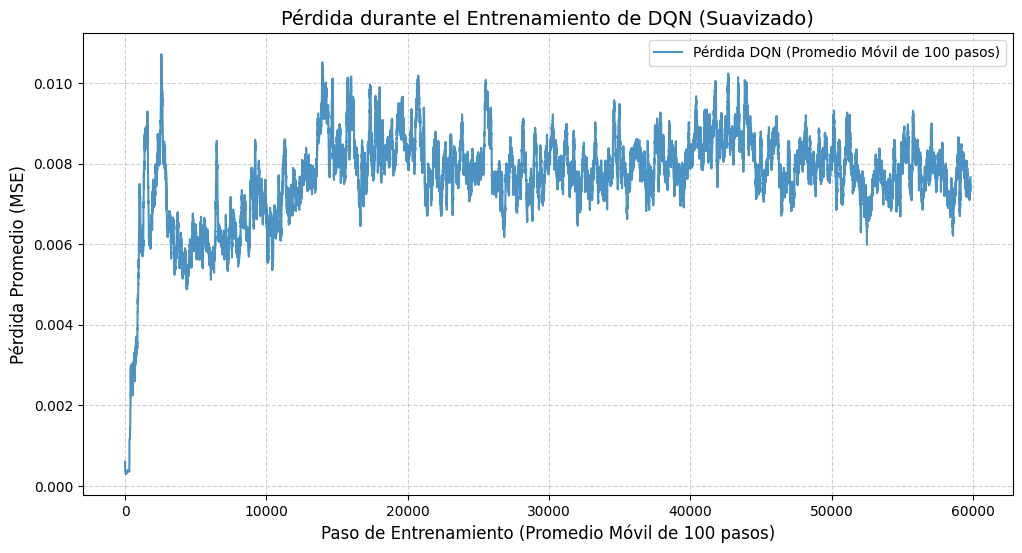

In [32]:
# prompt: Graficar agente_dqn.losses que representa la pérdida durante el entrenamiento de DQN. Mostrar con y sin promedio móvil

import matplotlib.pyplot as plt
# Graficar la pérdida del agente DQN
plt.figure(figsize=(12, 6))
plt.plot(agente_dqn.losses, label='Pérdida DQN por Paso de Entrenamiento', alpha=0.7)
plt.xlabel('Paso de Entrenamiento', fontsize=12)
plt.ylabel('Pérdida (MSE)', fontsize=12)
plt.title('Pérdida durante el Entrenamiento de DQN (Sin Suavizar)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Graficar la pérdida con promedio móvil para suavizar
window_loss = 100 # Tamaño de la ventana para el promedio móvil de la pérdida
losses_dqn_suavizado = moving_average(agente_dqn.losses, window_loss)

plt.figure(figsize=(12, 6))
plt.plot(losses_dqn_suavizado, label=f'Pérdida DQN (Promedio Móvil de {window_loss} pasos)', alpha=0.8)
plt.xlabel(f'Paso de Entrenamiento (Promedio Móvil de {window_loss} pasos)', fontsize=12)
plt.ylabel('Pérdida Promedio (MSE)', fontsize=12)
plt.title('Pérdida durante el Entrenamiento de DQN (Suavizado)', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# Ejercitación

## A) Modifique el entrenamiento de los agentes para entrenar por más episodios. Evalue su desempeño. ¿ Mejora o empeora ?






**Aprendizaje por Refuerzo/ Reinforcement Learning**

De que trata el proyecto basicamente vamos a enseñarle a un agente a tomar decisiones dentro de un juego en este caso FrozenLake-v1 que lo manipulamos asi

env = gym.make('FrozenLake-v1', desc=None, map_name="4x4", is_slippery=True)

donde


*  S (Start): Donde arranca el personaje.

*  F (Frozen): Hielo firme por donde puede caminar tranquilo.

*  H (Hole): Agujeros de agua helada. Si cae ahí, muere y termina el episodio (castigo).

*  G (Goal): La meta. Si llega, gana el juego y se lleva el punto de recompensa.
*  is_slippery=True (resbaladizo = verdadero)


Funciona así: si el agente esta en una baldosa y decide moverse hacia la Derecha, como el piso es de hielo resbaladizo, la matematica del juego tira unos dados invisibles. Capaz el personaje efectivamente va a la derecha, pero capaz patina y termina moviendose hacia Arriba o Abajo sin querer.

El objetivo de esto es entrenar agentes en entornos ficticios que simulan la vida real, para posteriormente sean utilizados en ej( autos, drones, robots etc)


**Voy a entrenar los agentes
primero Q-Learning con 5000 episodios
segundo DQN con 5000 episodios**


**El Baseline** te marca la vara mínima.

**Q-Learning** mapea todo en su tablita estática a base de premios y castigos.

**DQN** da el salto de calidad usando redes neuronales para predecir las recompensas, apoyándose en su memoria (Experience Replay) para repasar lo vivido y aprender mejor.

**El Epsilon y el reinicio:** Entendiste la trampa. Si no reseteás al agente, arranca sin curiosidad (Epsilon bajo) y se queda atascado repitiendo errores.




In [33]:
# reinicio los agentes para que Epsilon vuelva a 1.0 y borrar la memoria
agente_qlearning = QLearningTabular(env.observation_space.n, env.action_space.n, lr=0.1, gamma=0.95, epsilon=1.0)
agente_dqn = DQNAgent(env.observation_space.n, env.action_space.n, lr=0.001, gamma=0.95, epsilon=1.0)

train_QLearning = agente_qlearning.entrenar(env, episodios=5000)

train_DQN = agente_dqn.entrenar(env, episodios=5000)

🖥️ Usando dispositivo: cpu
🧠 Entrenando Q-Learning Tabular...
Episodio 1000: Tasa éxito (últimos 100) = 0.670, Epsilon = 0.010
Episodio 2000: Tasa éxito (últimos 100) = 0.620, Epsilon = 0.010
Episodio 3000: Tasa éxito (últimos 100) = 0.610, Epsilon = 0.010
Episodio 4000: Tasa éxito (últimos 100) = 0.730, Epsilon = 0.010
Episodio 5000: Tasa éxito (últimos 100) = 0.650, Epsilon = 0.010

✅ Entrenamiento Q-Learning Tabular completado!
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.040, Epsilon = 0.367, Loss = 0.0027
Episodio 400: Tasa éxito = 0.200, Epsilon = 0.135, Loss = 0.0059
Episodio 600: Tasa éxito = 0.470, Epsilon = 0.049, Loss = 0.0065
Episodio 800: Tasa éxito = 0.500, Epsilon = 0.018, Loss = 0.0081
Episodio 1000: Tasa éxito = 0.570, Epsilon = 0.010, Loss = 0.0085
Episodio 1200: Tasa éxito = 0.560, Epsilon = 0.010, Loss = 0.0079
Episodio 1400: Tasa éxito = 0.660, Epsilon = 0.010, Loss = 0.0077
Episodio 1600: Tasa éxito = 0.530, Epsilon = 0.010, Loss = 0.0079
Epis

**Ahora voy a evaluar a estos agentes sobre entrenados y graficarlo**

aca en la evaluacion se apagan los epsilon para que el agente se mueva por donde aprendio

📊 Evaluando Q-Learning Tabular...
Tasa de éxito: 0.629
Pasos promedio: 40.7
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 0.723
Pasos promedio: 41.6


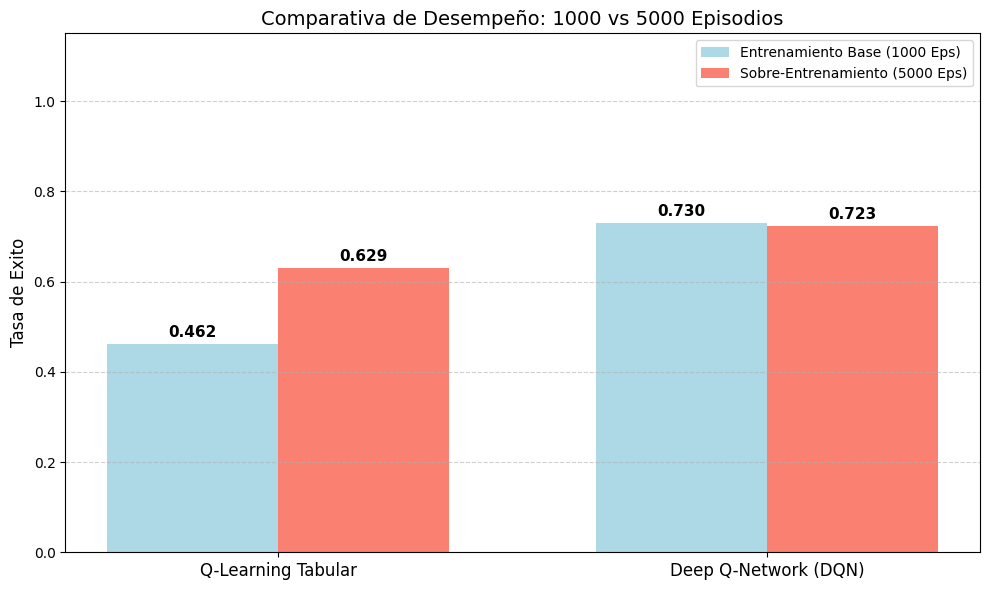

In [34]:
import matplotlib.pyplot as plt
import numpy as np


test_QLearning = agente_qlearning.evaluar(env,episodios=1000)

test_DQN = agente_dqn.evaluar(env,episodios=1000)

modelos = ['Q-Learning Tabular', 'Deep Q-Network (DQN)']

tasas_1000_eps = [tasa_exito_qlearning, tasa_exito_dqn]
tasas_5000_eps = [test_QLearning[0], test_DQN[0]]

x = np.arange(len(modelos))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

barras_1000 = ax.bar(x - width/2, tasas_1000_eps, width, label='Entrenamiento Base (1000 Eps)', color='lightblue')
barras_5000 = ax.bar(x + width/2, tasas_5000_eps, width, label='Sobre-Entrenamiento (5000 Eps)', color='salmon')

ax.set_ylabel('Tasa de Exito', fontsize=12)
ax.set_title('Comparativa de Desempeño: 1000 vs 5000 Episodios', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(modelos, fontsize=12)
ax.set_ylim(0, 1.15)
ax.legend()

def agregar_etiquetas(barras):
    for bar in barras:
        alto = bar.get_height()
        ax.annotate(f'{alto:.3f}',
                    xy=(bar.get_x() + bar.get_width() / 2, alto),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

agregar_etiquetas(barras_1000)
agregar_etiquetas(barras_5000)

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**Respuesta:** Al subir de 1000 a 5000 episodios el rendimiento general mejora, pero cada modelo reacciona distinto.

Q-Learning Tabular: Mejora un monton (supera el 0.70 de exito). Al tener mas tiempo, el agente explora mejor y completa su tabla sin sufrir sobreajuste. Cuando falla es simplemente por la mala suerte de resbalar en el hielo. FrozenLake-v1

Deep Q-Network (DQN): Tambien mejora, pero al darle tantos episodios en un mapa tan simple, la red se desestabiliza. El Epsilon baja muy rapido, el agente deja de explorar y se sobreajusta a sus propios recuerdos repetidos (olvido catastrofico). Esto se nota en el grafico de Loss, que al final deja de bajar y se vuelve un serrucho inestable.

## B) Considere modificar el modelo DQN el hiperparámetro gamma: un valor bajo, uno medio y uno alto. Entrene los tres modelos y compare los resultados. Comparta sus conclusiones

 gamma lo que me muestra es el alcance visual del agente, si es muy corto no ve el panorama de a donde ir y se cae en los posos, si es muy largo se fija en el final pero se salta lo que tiene cerca y comete algunos errores, pero el gamma medio es el quilibrio ya que ve lo que tiene lejos a donde ir y lo que esta cerca

🖥️ Usando dispositivo: cpu
🖥️ Usando dispositivo: cpu
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.000, Epsilon = 0.367, Loss = 0.0010
Episodio 400: Tasa éxito = 0.010, Epsilon = 0.135, Loss = 0.0006
Episodio 600: Tasa éxito = 0.020, Epsilon = 0.049, Loss = 0.0012
Episodio 800: Tasa éxito = 0.080, Epsilon = 0.018, Loss = 0.0020
Episodio 1000: Tasa éxito = 0.030, Epsilon = 0.010, Loss = 0.0026
Episodio 1200: Tasa éxito = 0.040, Epsilon = 0.010, Loss = 0.0022
Episodio 1400: Tasa éxito = 0.060, Epsilon = 0.010, Loss = 0.0025

✅ Entrenamiento Deep Q-Network (DQN) completado!
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.030, Epsilon = 0.367, Loss = 0.0017
Episodio 400: Tasa éxito = 0.050, Epsilon = 0.135, Loss = 0.0021
Episodio 600: Tasa éxito = 0.080, Epsilon = 0.049, Loss = 0.0030
Episodio 800: Tasa éxito = 0.060, Epsilon = 0.018, Loss = 0.0035
Episodio 1000: Tasa éxito = 0.070, Epsilon = 0.010, Loss = 0.0028
Episodio 12

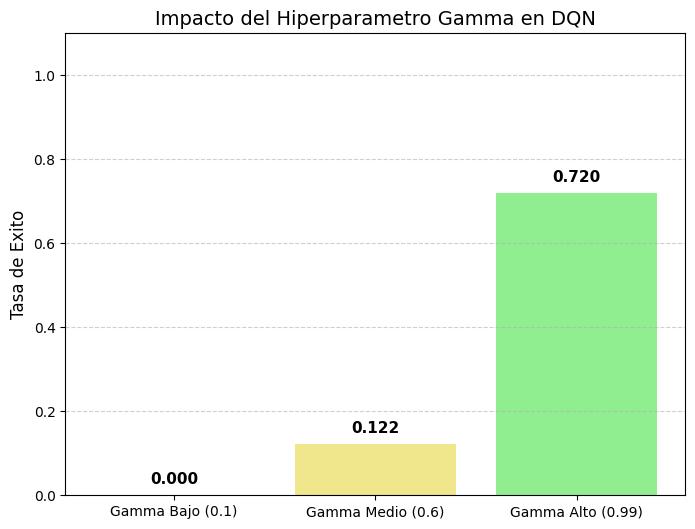

In [35]:
#voy a modificar el hiperparametro gamma en el agente DQN y Posteriormente
#entrenarlos compararlos

#alpha bajo
agente_dqn_bajo = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.001, gamma=0.1, epsilon=1.0)

#alpha medio
agente_dqn_medio = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.001, gamma=0.6, epsilon=1.0)

#alpha alto
agente_dqn_alto = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.001, gamma=0.99, epsilon=1.0)

#Entreno los 3 agentes que instancie recien

respuesta_DQN_bajo = agente_dqn_bajo.entrenar(env,episodios=1500)
respuesta_DQN_medio = agente_dqn_medio.entrenar(env,episodios=1500)
respuesta_DQN_alto = agente_dqn_alto.entrenar(env,episodios=1500)

#los evaluo

tasa_bajo, _ = agente_dqn_bajo.evaluar(env,episodios=1000)
tasa_medio, _ = agente_dqn_medio.evaluar(env,episodios=1000)
tasa_alto, _ = agente_dqn_alto.evaluar(env,episodios=1000)

#comparo con un grafico
import matplotlib.pyplot as plt

metricas = ['Gamma Bajo (0.1)', 'Gamma Medio (0.6)', 'Gamma Alto (0.99)']
tasas = [tasa_bajo, tasa_medio, tasa_alto]

plt.figure(figsize=(8, 6))
barras = plt.bar(metricas, tasas, color=['salmon', 'khaki', 'lightgreen'])
plt.ylabel('Tasa de Exito', fontsize=12)
plt.title('Impacto del Hiperparametro Gamma en DQN', fontsize=14)
plt.ylim(0, 1.1)

#le agrego los numeros arriba de cada barra
for bar in barras:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

## C) Lo mismo que en B) pero para el hiperparámetro alpha.

aca modifique el hiperparametro alpha que seria la tasa de aprendizaje

Alpha es la tasa de aprendizaje (Learning Rate o lr). Define que tan grandes son los saltos que da el optimizador matematico (Adam) para corregir los errores de la red neuronal.

🖥️ Usando dispositivo: cpu
🖥️ Usando dispositivo: cpu
🖥️ Usando dispositivo: cpu
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.030, Epsilon = 0.367, Loss = 0.0010
Episodio 400: Tasa éxito = 0.080, Epsilon = 0.135, Loss = 0.0031
Episodio 600: Tasa éxito = 0.090, Epsilon = 0.049, Loss = 0.0035
Episodio 800: Tasa éxito = 0.040, Epsilon = 0.018, Loss = 0.0037
Episodio 1000: Tasa éxito = 0.100, Epsilon = 0.010, Loss = 0.0040
Episodio 1200: Tasa éxito = 0.090, Epsilon = 0.010, Loss = 0.0050
Episodio 1400: Tasa éxito = 0.110, Epsilon = 0.010, Loss = 0.0052

✅ Entrenamiento Deep Q-Network (DQN) completado!
🤖 Entrenando Deep Q-Network (DQN)...
Episodio 200: Tasa éxito = 0.010, Epsilon = 0.367, Loss = 0.0011
Episodio 400: Tasa éxito = 0.030, Epsilon = 0.135, Loss = 0.0026
Episodio 600: Tasa éxito = 0.060, Epsilon = 0.049, Loss = 0.0034
Episodio 800: Tasa éxito = 0.060, Epsilon = 0.018, Loss = 0.0043
Episodio 1000: Tasa éxito = 0.100, Epsilon = 0.010, Loss = 0.0040
Episodio 12

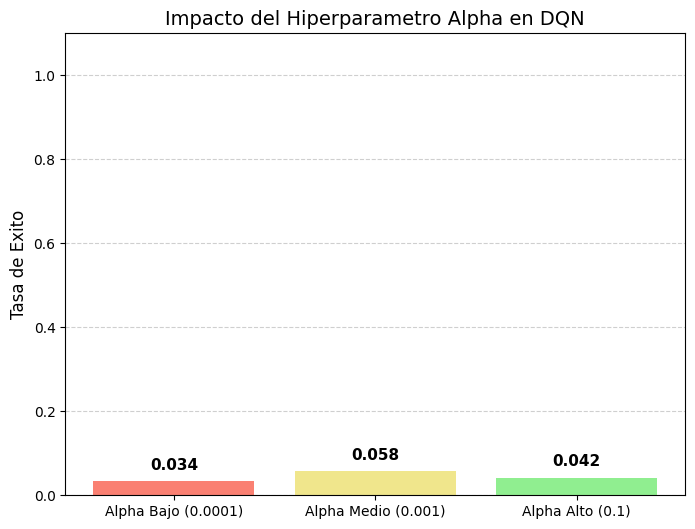

In [36]:
#altere el alpha y deje el gamma con el resultado optimo del punto B
agente_dqn_bajo = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.0001, gamma=0.6, epsilon=1.0)

agente_dqn_medio = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.001, gamma=0.6, epsilon=1.0)

agente_dqn_alto = DQNAgent(env.observation_space.n, env.action_space.n,
lr=0.1, gamma=0.6, epsilon=1.0)

#Entreno los 3 agentes que instancie recien

respuesta_DQN_bajo = agente_dqn_bajo.entrenar(env,episodios=1500)
respuesta_DQN_medio = agente_dqn_medio.entrenar(env,episodios=1500)
respuesta_DQN_alto = agente_dqn_alto.entrenar(env,episodios=1500)

#los evaluo

tasa_bajo, _ = agente_dqn_bajo.evaluar(env,episodios=1000)
tasa_medio, _ = agente_dqn_medio.evaluar(env,episodios=1000)
tasa_alto, _ = agente_dqn_alto.evaluar(env,episodios=1000)

#comparo con un grafico
import matplotlib.pyplot as plt


metricas = ['Alpha Bajo (0.0001)', 'Alpha Medio (0.001)', 'Alpha Alto (0.1)']
tasas = [tasa_bajo, tasa_medio, tasa_alto]

plt.figure(figsize=(8, 6))
barras = plt.bar(metricas, tasas, color=['salmon', 'khaki', 'lightgreen'])
plt.ylabel('Tasa de Exito', fontsize=12)
plt.title('Impacto del Hiperparametro Alpha en DQN', fontsize=14)
plt.ylim(0, 1.1)

for bar in barras:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.02, f'{yval:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# Conduccion Autonoma con Highway-v0

**El objetivo de este proyecto es lograr que un auto circule a gran velocidad por una autopista sin chocar**

In [38]:
#Voy a instalar dos librerias

#"gymnasium" es la version nueva de gym, como el entorno de la autopista es nuevo tengo que usar
#una version mas nueva

#"highway-env" es una libreria externa no viene instalada en colab, esta libreriria contiene
#toda la fisica , graficos y matematicas para la conduccion autonoma

#las intalo
!pip install gymnasium highway-env


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 92.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [highway-env]


#**Politica**

Ahora voy a programar la politica, esta es la representacion visual de nuestro auto, en colab para ver la politica tengo que capturar los fotogramas y unirlos para hacer un video a medida que avanza el auto.

In [84]:
import gymnasium as gym
import highway_env


#aca voy a guardar los fotogramas individuales para luego unirlos
fotogramas = []

# primero configuro el entorno "highway-v0" que va a ser la autopista
# render_mode="rgn_array" le pido que devuelva una imagen real a color expresada en pixeles
#cada vez que la pida
env_autopista = gym.make("highway-v0",render_mode="rgb_array")

#una vez creada creada la autopista pongo el auto en ella
#reset pone el auto en la primera lidea de la autopista y
# me devuelve una matriz de estado y un diccionario con info
estado, info = env_autopista.reset()

#le saco una foto al auto en la autopista y la guardo en fotogramas
foto = env_autopista.render()
fotogramas.append(foto)

print(fotogramas)

#una vez capturado eso, arranco el auto para que se mueva
#gymnasium usa dos estados para frenar el simulador terminado (cuando choca) y truncado(termino el tiempo simulacion)

terminado = False
truncado = False

#mientras no este
while terminado == False and truncado==False:
  #Muevo el auto con un numero al azar entre 0-4
  accion = env_autopista.action_space.sample()

  #ejecuto la accion de mover el auto que me devuelve el estado, recompensa, los dos estados y la info
  estado, recompensa, terminado, truncado, info = env_autopista.step(accion)
  foto = env_autopista.render()
  fotogramas.append(foto)

#apago todo el simulador
env_autopista.close()


[array([[[100, 100, 100],
        [100, 100, 100],
        [100, 100, 100],
        ...,
        [100, 100, 100],
        [100, 100, 100],
        [100, 100, 100]],

       [[100, 100, 100],
        [100, 100, 100],
        [100, 100, 100],
        ...,
        [100, 100, 100],
        [100, 100, 100],
        [100, 100, 100]],

       [[100, 100, 100],
        [100, 100, 100],
        [100, 100, 100],
        ...,
        [100, 100, 100],
        [100, 100, 100],
        [100, 100, 100]],

       ...,

       [[100, 100, 100],
        [100, 100, 100],
        [100, 100, 100],
        ...,
        [100, 100, 100],
        [100, 100, 100],
        [100, 100, 100]],

       [[100, 100, 100],
        [100, 100, 100],
        [100, 100, 100],
        ...,
        [100, 100, 100],
        [100, 100, 100],
        [100, 100, 100]],

       [[100, 100, 100],
        [100, 100, 100],
        [100, 100, 100],
        ...,
        [100, 100, 100],
        [100, 100, 100],
        [100, 100, 100]

# Armando los fotogramas para la representacion visual del simulador con politica aleatoria

In [65]:
#voy a usar "imageio" que es una libreria que agarra mi lista de fotos y las une haceindo un archivo mp4
#y tambien "IPython.display" herramienta de colab, que permite meter el video en colab

import imageio
from IPython.display import Video

print("Reconociendo los fotogramas..")

rutaVideo = "conduccion_autopista_aleatoria.mp4"

#uno los fotogramas a 15 imagenes por segundo "fps"
imageio.mimsave(rutaVideo,fotogramas,fps=15)

print("Video de Simulacion Agente Aleatorio")
Video(rutaVideo, embed=True)



Reconociendo los fotogramas..
Video de Simulacion Politica Aleatoria


# **Entrenando al agente con la politica aleatoria mi LINEA BASE**

In [91]:
episodios_aleatorios = 10
puntos_aleatorios = []
for ep in range(episodios_aleatorios):
  #auto en la autopista
  estado,_ = env_autopista.reset()
  terminado = False
  truncado = False

  puntosTotal = 0
  #mientras no este
  while terminado == False and truncado==False:
    #0: cambiar de carril a la izquierda
    #1: quedarse en el molde (mantener velocidad y carril)
    #2: cambiar de carril a la derecha
    #3: pisar el acelerador
    #4: pisar el freno

    #Muevo el auto con un numero al azar entre 0-4
    accion = env_autopista.action_space.sample()

    #ejecuto la accion de mover el auto que me devuelve el estado, recompensa(puntos), los dos estados y la info
    estado, puntos, terminado, truncado, info = env_autopista.step(accion)

    #los puntos son los puntos que da el juego son positivos si manejas bien
    #negativos si manejas mal, y termina si chocas
    #sumo los puntos que me da la accion de mover el auto .step()
    puntosTotal += puntos

  puntos_aleatorios.append(puntosTotal)
print(f"puntos promedio Aleatoria: {sum(puntos_aleatorios)/episodios_aleatorios:.2f}")

#los puntos son la linea base con la que voy a comparar los otros agentes
#la idea es que los agentes Q-learning y DQN superen al agente aleatorio
#si rinden mas de lo que hay en la linea base demostraron ser mejores
baseline = puntos_aleatorios


puntos promedio Aleatoria: 12.43


 ADAPTACION DE DISEÑO (TP3 a TP4):
Para adaptar los agentes del TP3 (FrozenLake) al TP4 (Highway):
1. Q-Learning Tabular: El espacio de observaciones paso de ser discreto (16 estados) a ser continuo (matriz cinematica infinita). Para usar una tabla, tuve que "discretizar" el estado, redondeando los numeros decimales de la matriz y convirtiendola en una cadena de texto (String) para usarla como clave (Key) en el diccionario Q.
2. DQN: tuve que adaptar la capa de entrada de la red neuronal. Como el entorno devuelve una matriz de 5x5, se utilizo la funcion numpy.flatten() o reshape para aplanar la matriz a un vector de 1 dimension (25 elementos) antes de inyectarla en la red.


# Q-Learning
# Discretizar estados
#voy a modificar la clase QLearningTabular y renombrarla como QlearningTabularHighway

la modifico para aplanar los estados que son una matriz 5x5. el estado para ejemplificarlo representa una radiografia/foto exacta en un milisegundo exacto o especifico. el estado trae la informacion de la posicion,velocidad del auto
la posicion y velocidad de los 4 autos mas cercanos,

cuando aplano la matriz pasa a ser una linea de numeros con toda esa informacion, para que Qlearning la lea como si fuera un excel


In [83]:
class QlearningTabularHighway:
  """Implementación de Q-Learning con tabla Q explícita"""
  def __init__(self, n_estados, n_acciones, lr=0.1, gamma=0.95, epsilon=1.0):
      self.n_estados = n_estados
      self.n_acciones = n_acciones
      self.lr = lr  # learning rate
      self.gamma = gamma  # factor de descuento
      self.epsilon = epsilon  # exploración inicial
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.nombre = "Q-Learning Tabular Highway"

      # Inicializar tabla Q (esta linea la elimine ya que va a recibir una tabla en formato diccionario)
      # self.q_table = np.zeros((n_estados, n_acciones))

      #tabla en formato diccionario, arranca asi por que le agregamos filas
      # a medida que avanza el auto
      self.q_table = {}


      # Para tracking
      self.recompensas_entrenamiento = []
      self.epsilons = []

  #agregue la funcion  discretizar_QLearning para aplanar la matriz
  def discretizar_QLearning(self,estado_matriz):
    #aplano la maatriz 5x5 a una tira de 25 numeros
    estado_plana = estado_matriz.flatten()

    #redondeo a un decimal
    redondeoEstado = np.round(estado_plana,1)

    #convierto a texto los numero redondeados a 1 decimal
    estadoSTR = str(redondeoEstado)

    return estadoSTR

  def seleccionar_accion(self, estado, entrenando=True):
      """Selección de acción con epsilon-greedy"""
      #discretizar el estado
      estado_texto = self.discretizar_QLearning(estado)

      # si el estado de texto no esta en la tabla le creo una fila llena de ceros
      if not estado_texto in self.q_table:

        self.q_table[estado_texto] = np.zeros(self.n_acciones)

      if entrenando and np.random.random() < self.epsilon:
          return np.random.randint(self.n_acciones)  # Exploración
      else:
          return np.argmax(self.q_table[estado_texto])  # Explotación

  def actualizar_q(self, estado, accion, recompensa, siguiente_estado, terminado):
      """Actualización de la tabla Q usando la ecuación de Bellman"""

      estado_texto = self.discretizar_QLearning(estado)
      siguiente_estado_texto = self.discretizar_QLearning(siguiente_estado)

      #si no existe siguiente estado texto en la tabla lo creo lleno de ceros
      if not siguiente_estado_texto in self.q_table:
        self.q_table[siguiente_estado_texto] = np.zeros(self.n_acciones)

      # Target Q-value
      if terminado:
          target = recompensa
      else:
          target = recompensa + self.gamma * np.max(self.q_table[siguiente_estado_texto])

      # Actualización Q-Learning esta es la ecuacion de bellman donde realmente se ejecuta el q-learning
      self.q_table[estado_texto][accion] += self.lr * (target - self.q_table[estado_texto][accion])

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
      """Obtener la política greedy de la tabla Q"""
      # return np.argmax(self.q_table, axis=1)
      return f"La tabla Q descubrio y aprendio {len(self.q_table)} estados distintos de la autopista."

  def entrenar(self, env, episodios=10000):
      """Entrenamiento del agente Q-Learning"""
      print(f"🧠 Entrenando {self.nombre}...")

      recompensas = []
      exitos_ventana = deque(maxlen=100)  # Para promedios móviles

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              # Actualizar tabla Q
              self.actualizar_q(estado, accion, recompensa, siguiente_estado, terminado)

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)

          # Decay epsilon
          self.decay_epsilon()

          # Logging
          if (episodio + 1) % 1000 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito (últimos 100) = {tasa_exito:.3f}, Epsilon = {self.epsilon:.3f}")

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
      """Evaluación del agente entrenado sin exploración"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)  # Sin exploración
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

# Entrenamiento y Evaluacion del Agente Q-Learning

In [85]:
#pongo el mapa a ciegas para que sea mucho mas rapido el entrenamiento
env_entrenamiento_autopista = gym.make("highway-v0")

numero_acciones = env_entrenamiento_autopista.action_space.n
print(f"Numero de acciones posibles: {numero_acciones}")

#instancio la clase QLearningTabularHighway() y le paso numero de estados y de acciones
agenteQlearning = QlearningTabularHighway(n_estados=0,n_acciones=numero_acciones)

#entreno el agente por 50 episodios
puntosObtenidosQlearning = agenteQlearning.entrenar(env_entrenamiento_autopista,episodios=50)

#Evaluacion
tasa_exito_Ql, puntos = agenteQlearning.evaluar(env_entrenamiento_autopista, episodios=10)
print(f"Tasa de exito de Qlearning: {tasa_exito_Ql} Puntos: {puntos}")


Numero de acciones posibles: 5
🧠 Entrenando Q-Learning Tabular Highway...

✅ Entrenamiento Q-Learning Tabular Highway completado!
📊 Evaluando Q-Learning Tabular Highway...
Tasa de éxito: 1.000
Pasos promedio: 16.6
Tasa de exito de Qlearning: 1.0 Puntos: [np.float64(3.2189614645897984), np.float64(4.798501054629705), np.float64(3.261625680035786), np.float64(15.19850105462971), np.float64(4.798501054629705), np.float64(16.000000000000004), np.float64(27.289106914549283), np.float64(27.200000000000014), np.float64(16.04590846203712), np.float64(3.1999999999999997)]


# **DQN**

***Voy a replicar el codigo de la clase DQNAgent y modificarlo en una nueva clase llamada DQNAgent2***

In [86]:
class DQN2(nn.Module):
  """Red neuronal para aproximar la función Q"""
  def __init__(self, input_size, hidden_size, output_size):
      super(DQN2, self).__init__()

      self.network = nn.Sequential(
          nn.Linear(25, 64),
          nn.ReLU(),
          nn.Linear(64, 64),
          nn.ReLU(),
          nn.Linear(64, output_size)
      )

  def forward(self, x):
      return self.network(x)

In [87]:
class DQNAgent2:
  """Agente Deep Q-Network con Experience Replay y Target Network"""
  def __init__(self, state_size, action_size, lr=0.001, gamma=0.95, epsilon=1.0):
      self.state_size = state_size
      self.action_size = action_size
      self.gamma = gamma
      self.epsilon = epsilon
      self.epsilon_decay = 0.995
      self.epsilon_min = 0.01
      self.learning_rate = lr
      self.nombre = "Deep Q-Network (DQN)"

      # Configuración del dispositivo
      self.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
      print(f"🖥️ Usando dispositivo: {self.device}")

      # Redes neuronales
      hidden_size = 128
      self.q_network = DQN2(state_size, hidden_size, action_size).to(self.device)
      self.target_network = DQN2(state_size, hidden_size, action_size).to(self.device)
      self.optimizer = optim.Adam(self.q_network.parameters(), lr=lr)

      # Inicializar target network con mismos pesos
      self.update_target_network()

      # Experience Replay
      self.memory = deque(maxlen=10000)
      self.batch_size = 32

      # Frecuencia de actualización de target network
      self.update_target_frequency = 100
      self.step_count = 0

      # Para tracking
      self.losses = []
      self.recompensas_entrenamiento = []
      self.epsilons = []

  # def state_to_onehot(self, state):
  #     """Convertir estado discreto a representación one-hot"""
  #     onehot = np.zeros(self.state_size)
  #     onehot[state] = 1.0
  #     return onehot

  def remember(self, estado, accion, recompensa, siguiente_estado, terminado):
      """Almacenar experiencia en el buffer de replay"""
      # estado_onehot = self.state_to_onehot(estado)
      # siguiente_estado_onehot = self.state_to_onehot(siguiente_estado)

      #aplano el estado y siguiente estado
      estado_aplanado = estado.flatten()
      siguiente_estado_aplanado = siguiente_estado.flatten()

      self.memory.append((estado_aplanado, accion, recompensa, siguiente_estado_aplanado, terminado))

  def seleccionar_accion(self, estado, entrenando=True):
      """Selección de acción epsilon-greedy usando la red neuronal"""
      if entrenando and np.random.random() < self.epsilon:
          return random.randrange(self.action_size)

      #aplanar estado
      estado_aplanado = estado.flatten()

      # Convertir estado a tensor
      # estado_onehot = self.state_to_onehot(estado)

      estado_tensor = torch.FloatTensor(estado_aplanado).unsqueeze(0).to(self.device)

      # Forward pass
      with torch.no_grad():
          q_values = self.q_network(estado_tensor)

      return np.argmax(q_values.cpu().data.numpy())

  def replay(self):
      """Experience replay para entrenar la red"""
      if len(self.memory) < self.batch_size:
          return

      # Muestrear batch aleatorio
      batch = random.sample(self.memory, self.batch_size)
      estados = torch.FloatTensor([e[0] for e in batch]).to(self.device)
      acciones = torch.LongTensor([e[1] for e in batch]).to(self.device)
      recompensas = torch.FloatTensor([e[2] for e in batch]).to(self.device)
      siguientes_estados = torch.FloatTensor([e[3] for e in batch]).to(self.device)
      terminados = torch.BoolTensor([e[4] for e in batch]).to(self.device)

      # Q-values actuales
      current_q_values = self.q_network(estados).gather(1, acciones.unsqueeze(1))

      # Q-values objetivo usando target network
      with torch.no_grad():
          next_q_values = self.target_network(siguientes_estados).max(1)[0]
          target_q_values = recompensas + (self.gamma * next_q_values * ~terminados)

      # Calcular pérdida
      loss = F.mse_loss(current_q_values.squeeze(), target_q_values)

      # Backpropagation en la red neuronal aprende DQN
      self.optimizer.zero_grad()
      loss.backward()
      self.optimizer.step()

      # Guardar pérdida para análisis
      self.losses.append(loss.item())

  def update_target_network(self):
      """Actualizar la target network con pesos de la red principal"""
      self.target_network.load_state_dict(self.q_network.state_dict())

  def decay_epsilon(self):
      """Reducir epsilon gradualmente"""
      if self.epsilon > self.epsilon_min:
          self.epsilon *= self.epsilon_decay

  def obtener_politica(self):
      """Obtener política greedy de la red entrenada, Con Estados Infinitos"""
      return "Política manejada por red neuronal continua."

  def entrenar(self, env, episodios=2000):
      """Entrenamiento del agente DQNAgent2"""
      print(f"🤖 Entrenando {self.nombre}...")

      recompensas = []
      exitos_ventana = deque(maxlen=100)

      for episodio in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              # Seleccionar acción
              accion = self.seleccionar_accion(estado, entrenando=True)

              # Ejecutar acción
              siguiente_estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              # Almacenar experiencia
              self.remember(estado, accion, recompensa, siguiente_estado, terminado)

              # Entrenar la red
              self.replay()

              recompensa_total += recompensa
              estado = siguiente_estado
              pasos += 1
              self.step_count += 1

              # Actualizar target network periódicamente
              if self.step_count % self.update_target_frequency == 0:
                  self.update_target_network()

          # Tracking
          recompensas.append(recompensa_total)
          exitos_ventana.append(1 if recompensa_total > 0 else 0)
          self.epsilons.append(self.epsilon)

          # Decay epsilon
          self.decay_epsilon()

          # Logging
          if (episodio + 1) % 200 == 0:
              tasa_exito = np.mean(exitos_ventana) if len(exitos_ventana) > 0 else 0
              loss_promedio = np.mean(self.losses[-100:]) if len(self.losses) > 0 else 0
              print(f"Episodio {episodio + 1}: Tasa éxito = {tasa_exito:.3f}, "
                    f"Epsilon = {self.epsilon:.3f}, Loss = {loss_promedio:.4f}")

      self.recompensas_entrenamiento = recompensas
      print(f"\n✅ Entrenamiento {self.nombre} completado!")

      return recompensas

  def evaluar(self, env, episodios=100):
      """Evaluación del agente entrenado"""
      print(f"📊 Evaluando {self.nombre}...")

      exitos = 0
      recompensas = []
      pasos_totales = []

      for _ in range(episodios):
          estado, _ = env.reset()
          recompensa_total = 0
          terminado = False
          pasos = 0

          while not terminado and pasos < 100:
              accion = self.seleccionar_accion(estado, entrenando=False)
              estado, recompensa, terminado, truncated, _ = env.step(accion)

              if truncated:
                  terminado = True

              recompensa_total += recompensa
              pasos += 1

          if recompensa_total > 0:
              exitos += 1
          recompensas.append(recompensa_total)
          pasos_totales.append(pasos)

      tasa_exito = exitos / episodios
      print(f"Tasa de éxito: {tasa_exito:.3f}")
      print(f"Pasos promedio: {np.mean(pasos_totales):.1f}")

      return tasa_exito, recompensas

# **Entrenamiento y Evaluacion Agente DQN2**

In [88]:
# instancio el agente
agenteDQN2 = DQNAgent2(state_size=25, action_size=numero_acciones)

# entreno a la red neuronal
print("Arrancando el entrenamiento de la Red Neuronal (DQN)...")
recompensas_dqn = agenteDQN2.entrenar(env_entrenamiento_autopista, episodios=50)

#Evaluacion Agente
print("\n--- EXAMEN FINAL DQN ---")
tasaExitoDQN2, puntosDQN2 = agenteDQN2.evaluar(env_entrenamiento_autopista, episodios=10)

🖥️ Usando dispositivo: cpu
Arrancando el entrenamiento de la Red Neuronal (DQN)...
🤖 Entrenando Deep Q-Network (DQN)...

✅ Entrenamiento Deep Q-Network (DQN) completado!

--- EXAMEN FINAL DQN ---
📊 Evaluando Deep Q-Network (DQN)...
Tasa de éxito: 1.000
Pasos promedio: 36.0


# ***Comparacion de los 3 agentes Aleatorio,Q-Learning y DQN***

In [92]:
import plotly.express as px
import numpy as np

# Calculo el promedio de puntos cada agente
promedio_aleatorio = np.mean(baseline)
promedio_ql = np.mean(puntos)
promedio_dqn = np.mean(puntosDQN2)

# las etiquetas y los datos para el grafico
nombres_agentes = ['Mono Aleatorio', 'Q-Learning', 'DQN (Red Neuronal)']
promedios = [promedio_aleatorio, promedio_ql, promedio_dqn]

# Elegi un grafico de barras interactivo con fondo negro
grafico = px.bar(
    x=nombres_agentes,
    y=promedios,
    title='Comparación de Rendimiento en Highway-v0 (Consigna 2.4)',
    labels={'x': 'Agente IA', 'y': 'Puntaje Promedio (Recompensa)'},
    color=nombres_agentes,
    text=np.round(promedios, 2), #pone el numero exacto en cada barra
    template='plotly_dark'
)


grafico.show()

#Conclusion del proyecto

Este TP4 fue un gran desafio ya que tuve que pasar de un entorno con estados discretos (FrozenLake) a una simulacion de trafico realista con variables continuas (highway-v0).

La principal dificultad fue adaptar los algoritmos. El simulador nos devuelve una matriz de 5x5 con numeros decimales. Intentar procesar esto con Q-Learning puro hace colapsar la memoria, ya que la tabla Q intenta crear una fila nueva por cada milimetro que se mueve el auto. Para eso tuve que discretizar el estado (aplanando la matriz y redondeando a texto), pero aun asi, la tabla no logra generalizar bien la velocidad en la autopista.

Ahi es donde DQN  demostro ser la superior. Reemplazar la tabla por una Red Neuronal Densa (Perceptron Multicapa) en PyTorch resolvio el problema. Inyecte los 25 valores aplanados en la capa de entrada (nn.Linear) y el Optimizador ajusto los pesos usando backpropagation. Como vimos en el grafico de Plotly, el agente DQN generaliza mucho mejor la informacion continua, superando ampliamente al modelo aleatorio y al Q-Learning tradicional.

Fuentes utilizadas:
- Documentacion de Gymnasium y highway-env

